In [1]:
# !pip install statsmodels
# !pip install --no-cache-dir --ignore-installed pandas statsmodels numpy
# !pip install --no-cache-dir --force-reinstall pandas seaborn

In [2]:
import numpy as np 
import pandas as pd 
import os
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import tensorflow

# Disable HTML display for DataFrames to prevent IPython from calling the broken html module
pd.set_option('display.notebook_repr_html', False)

# Your standard imports
import tensorflow as tf
from statsmodels.tsa.stattools import adfuller
from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from keras import callbacks
from tensorflow.keras import layers, Sequential, callbacks
from tensorflow.keras.layers import Conv2D, Flatten, Dense, LSTM, Dropout, GRU, Bidirectional, Conv1D, MaxPooling1D
from tensorflow.keras.optimizers import SGD, Adam
import math
from sklearn.metrics import mean_squared_error
from tensorflow.keras.optimizers.schedules import ExponentialDecay
import warnings
warnings.filterwarnings('ignore')


C:\Users\tanni\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
data=pd.read_csv("traffic.csv")
data.head()

              DateTime  Junction  Vehicles           ID
0  2015-11-01 00:00:00         1        15  20151101001
1  2015-11-01 01:00:00         1        13  20151101011
2  2015-11-01 02:00:00         1        10  20151101021
3  2015-11-01 03:00:00         1         7  20151101031
4  2015-11-01 04:00:00         1         9  20151101041

In [5]:
data['DateTime']=pd.to_datetime(data['DateTime'])

data["Year"]=data['DateTime'].dt.year

data["Month"]=data['DateTime'].dt.month

data["Date_no"]=data['DateTime'].dt.day

data["Hour"]=data['DateTime'].dt.hour

data["Day"]= data['DateTime'].dt.strftime("%A")
data

                 DateTime  Junction  Vehicles           ID  Year  Month  \
0     2015-11-01 00:00:00         1        15  20151101001  2015     11   
1     2015-11-01 01:00:00         1        13  20151101011  2015     11   
2     2015-11-01 02:00:00         1        10  20151101021  2015     11   
3     2015-11-01 03:00:00         1         7  20151101031  2015     11   
4     2015-11-01 04:00:00         1         9  20151101041  2015     11   
...                   ...       ...       ...          ...   ...    ...   
48115 2017-06-30 19:00:00         4        11  20170630194  2017      6   
48116 2017-06-30 20:00:00         4        30  20170630204  2017      6   
48117 2017-06-30 21:00:00         4        16  20170630214  2017      6   
48118 2017-06-30 22:00:00         4        22  20170630224  2017      6   
48119 2017-06-30 23:00:00         4        12  20170630234  2017      6   

       Date_no  Hour     Day  
0            1     0  Sunday  
1            1     1  Sunday  
2     

<Axes: xlabel='Date_no', ylabel='Vehicles'>

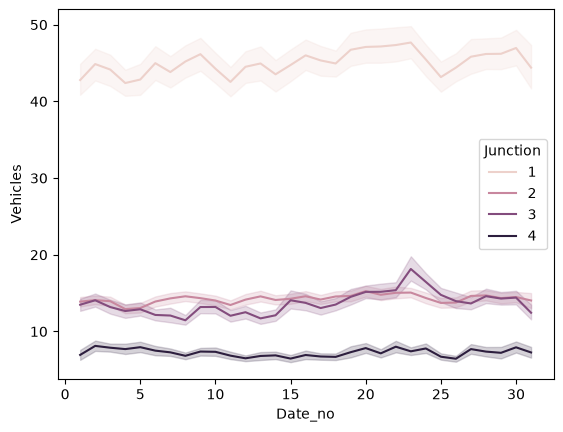

In [6]:
sns.lineplot(x=data['Date_no'],y="Vehicles",data=data,hue='Junction')

In [7]:
data = data[(data['Junction'] == 1)]
def Normalize(df,col):
    average = df[col].mean()
    stdev = df[col].std()
    df_normalized = (df[col] - average) / stdev
    df_normalized = df_normalized.to_frame()
    return df_normalized, average, stdev

def Difference(df,col, interval):
    diff = []
    for i in range(interval, len(df)):
        value = df[col][i] - df[col][i - interval]
        diff.append(value)
    return diff

In [8]:
df_N, av, std = Normalize(data, "Vehicles")
Diff = Difference(df_N, col="Vehicles", interval=(24*7)) #taking a week's diffrence
df_N = df_N[24*7:]
df_N.columns = ["Norm"]
df_N["Diff"]= Diff
df = df_N["Diff"].dropna()
df = df.to_frame()
df.head()

         Diff
168 -0.086925
169  0.130387
170  0.043462
171  0.043462
172  0.043462

In [9]:
df.shape

(14424, 1)

In [10]:
def Split_data(df):
    training_size = int(len(df)*0.80)
    data_len = len(df)
    train, test = df[0:training_size],df[training_size:data_len] 
    train, test = train.values.reshape(-1, 1), test.values.reshape(-1, 1)
    return train, test

df_train, df_test = Split_data(df)

In [11]:
def TnF(df):
    end_len = len(df)
    X = []
    y = []
    steps = 32
    for i in range(steps, end_len):
        X.append(df[i - steps:i, 0])
        y.append(df[i, 0])
    X, y = np.array(X), np.array(y)
    return X ,y

def FeatureFixShape(train, test):
    train = np.reshape(train, (train.shape[0], train.shape[1], 1))
    test = np.reshape(test, (test.shape[0],test.shape[1],1))
    return train, test

X_train, y_train = TnF(df_train)
X_test, y_test = TnF(df_test)
X_train, X_test = FeatureFixShape(X_train, X_test)

In [12]:
X_train, X_test = FeatureFixShape(X_train, X_test)
from sklearn.metrics import mean_absolute_error

lr_schedule = ExponentialDecay(
    initial_learning_rate=0.01,
    decay_steps=10000,
    decay_rate=0.9)

def MLP_model(X_Train, y_Train, X_Test, y_Test):
    X_Train = np.squeeze(X_Train)  # This line removes the unnecessary dimension
    X_Test = np.squeeze(X_Test)    # Do the same for the test data
    early_stopping = callbacks.EarlyStopping(min_delta=0.001,patience=10, restore_best_weights=True) 
    model = Sequential()
    model.add(Dense(100, activation='relu', input_dim=X_Train.shape[1]))
    model.add(Dropout(0.2))
    model.add(Dense(20, activation='relu', input_dim=X_Train.shape[1]))
    model.add(Dropout(0.2))
    model.add(Dense(1))
    model.compile(optimizer=SGD(learning_rate=lr_schedule, momentum=0.9),loss='mean_squared_error')
    model.fit(X_Train, y_Train, validation_data=(X_test, y_test), epochs=50, batch_size=120, callbacks=[early_stopping])
    pred_MLP = model.predict(X_Test)
    return pred_MLP

In [13]:
def RMSE_Value(test,predicted):
    rmse = math.sqrt(mean_squared_error(test, predicted))
    print("The root mean squared error is {}.".format(rmse))
    return rmse

def MAE_Value(test,predicted):
    mae = mean_absolute_error(test, predicted)
    print("The MAE is {}.".format(mae))
    return mae

#To plot the comparitive plot of targets and predictions
def PredictionsPlot(test,predicted,m):
    plt.figure(figsize=(12,5))
    plt.plot(test, color=colors[m],label="True Value",alpha=0.5 )
    plt.plot(predicted,label="Predicted Values")
    plt.title("Traffic Prediction Vs True values")
    plt.xlabel("DateTime")
    plt.ylabel("Number of Vehicles")
    plt.legend()
    plt.show()

In [14]:
Pred_MLP = MLP_model(X_train,y_train,X_test, y_test)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0835 - val_loss: 0.0730
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0590 - val_loss: 0.0663
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0563 - val_loss: 0.0634
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0531 - val_loss: 0.0617
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0523 - val_loss: 0.0602
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0509 - val_loss: 0.0593
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0505 - val_loss: 0.0591
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0505 - val_loss: 0.0590
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0500 - val_loss: 0.0577
Epoch 10/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0485 - val_loss: 0.0571
Epoch 11/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0498 - val_loss: 0.0575
Epoch 12/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0486 - val_l

The root mean squared error is 0.23809453922824153.
The MAE is 0.17098039448383426.


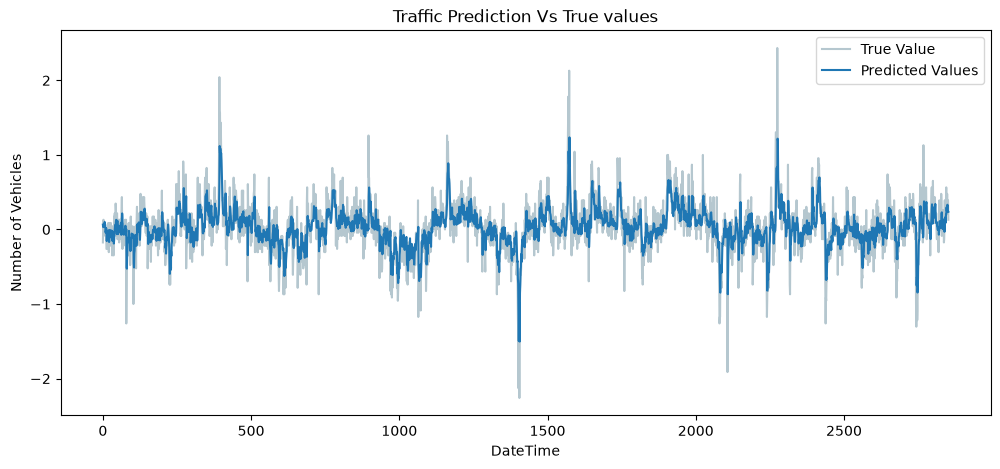

In [15]:
colors = ["#6D91A1","#74B3CE1","#536D7A","#3E535B"]
RMSE_MLP = RMSE_Value(y_test, Pred_MLP)
MAE_MLP = MAE_Value(y_test, Pred_MLP)
PredictionsPlot(y_test, Pred_MLP, 0)

In [16]:
def inverse_difference(last_ob, value):
    inversed = value + last_ob
    return inversed

def Sub_Plots(df_1, df_2,title,m):
    fig, axes = plt.subplots(1, 2, figsize=(18,4), sharey=True)
    fig.suptitle(title)
    
    pl_1=sns.lineplot(ax=axes[0],data=df_1,color=colors[m])
    axes[0].set(ylabel ="Prediction")
    
    pl_2=sns.lineplot(ax=axes[1],data=df_2["Vehicles"],color="#3E535B")
    axes[1].set(ylabel ="Original")

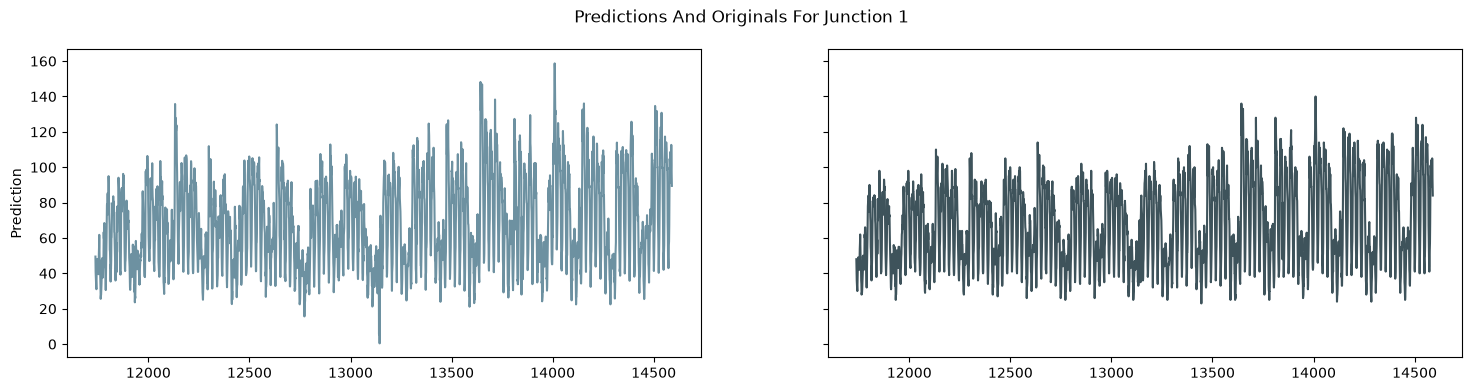

In [17]:
recover = df_N.Norm[-2854:-1].to_frame()
recover["Pred"]= globals()[f"Pred_MLP"]
Transform_reverssed = inverse_difference(recover.Norm, recover.Pred).to_frame()
Transform_reverssed.columns = ["Pred_Normed"]
Final_Pred = (Transform_reverssed.values* std) + av
Transform_reverssed["Pred_Final"] = Final_Pred
Sub_Plots(Transform_reverssed["Pred_Final"], data[-2854:-1],"Predictions And Originals For Junction 1", 0)

In [18]:
def GRU_model(X_Train, y_Train, X_Test, y_Test):
    early_stopping = callbacks.EarlyStopping(min_delta=0.001,patience=10, restore_best_weights=True) 
    #callback delta 0.01 may interrupt the learning.
    
    #The GRU model 
    model = Sequential()
    model.add(GRU(units=100, return_sequences=True, input_shape=(X_Train.shape[1],1), activation='tanh'))
    model.add(Dropout(0.2))
    model.add(GRU(units=20, input_shape=(X_Train.shape[1],1), activation='tanh'))
    model.add(Dropout(0.2))
    model.add(Dense(units=1))

    #Compiling the model
    model.compile(optimizer=SGD(learning_rate=lr_schedule, momentum=0.9),loss='mean_squared_error')
    model.fit(X_Train,y_Train, validation_data=(X_Test, y_Test), epochs=50, batch_size=120,callbacks=[early_stopping])
    pred_GRU= model.predict(X_Test)
    return pred_GRU

In [19]:
def LSTM_model(X_Train, y_Train, X_Test, y_Test):
    early_stopping = callbacks.EarlyStopping(min_delta=0.001,patience=10, restore_best_weights=True) 
    
    #The LSTM model 
    model = Sequential()
    model.add(LSTM(units=100, return_sequences=True, input_shape=(X_Train.shape[1],1), activation='tanh'))
    model.add(Dropout(0.2))
    model.add(LSTM(units=20, input_shape=(X_Train.shape[1],1), activation='tanh'))
    model.add(Dropout(0.2))
    model.add(Dense(units=1))
    
    #Compiling the model
    model.compile(optimizer=SGD(learning_rate=lr_schedule, momentum=0.9),loss='mean_squared_error')
    model.fit(X_Train,y_Train, validation_data=(X_Test, y_Test), epochs=50, batch_size=120,callbacks=[early_stopping])
    pred_LSTM = model.predict(X_Test)
    return pred_LSTM

In [20]:
Pred_GRU = GRU_model(X_train,y_train,X_test,y_test)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 17s 110ms/step - loss: 0.0565 - val_loss: 0.0616
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - loss: 0.0482 - val_loss: 0.0599
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 92ms/step - loss: 0.0479 - val_loss: 0.0588
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - loss: 0.0468 - val_loss: 0.0582
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 104ms/step - loss: 0.0458 - val_loss: 0.0575
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step - loss: 0.0459 - val_loss: 0.0578
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 20s 99ms/step - loss: 0.0458 - val_loss: 0.0568
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 98ms/step - loss: 0.0455 - val_loss: 0.0564
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - loss: 0.0454 - val_loss: 0.0575
Epoch 10/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 101ms/step - loss: 0.0452 - val_loss: 0.0561
Epoch 11/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 97ms/step - loss: 0.0450 - val_loss: 0.0564
Epoch 12/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 100m

The root mean squared error is 0.23753223894500966.
The MAE is 0.17158167184125792.


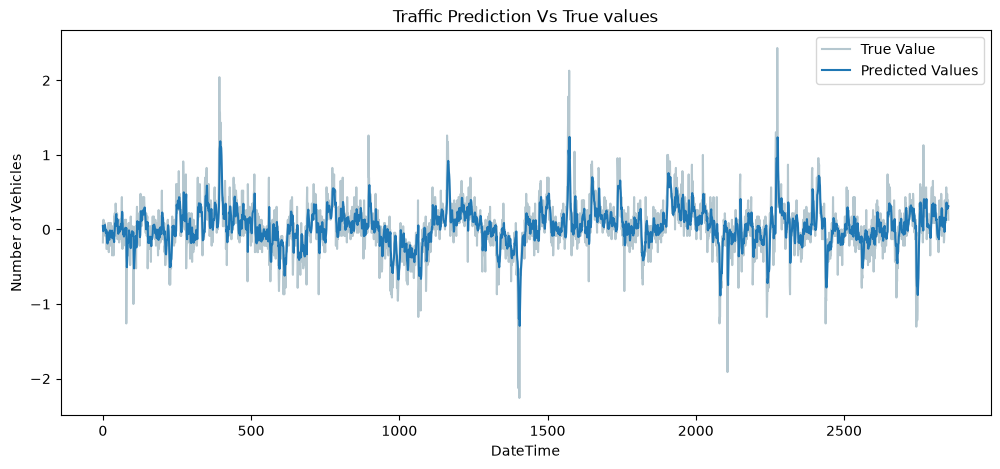

In [21]:
RMSE_GRU = RMSE_Value(y_test, Pred_GRU)
MAE_GRU = MAE_Value(y_test, Pred_GRU)
PredictionsPlot(y_test, Pred_GRU, 0)

In [22]:
Pred_LSTM = LSTM_model(X_train,y_train,X_test, y_test)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 16s 112ms/step - loss: 0.0714 - val_loss: 0.0818
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - loss: 0.0601 - val_loss: 0.0779
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - loss: 0.0571 - val_loss: 0.0749
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - loss: 0.0560 - val_loss: 0.0727
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 112ms/step - loss: 0.0546 - val_loss: 0.0711
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - loss: 0.0539 - val_loss: 0.0697
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - loss: 0.0534 - val_loss: 0.0686
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 118ms/step - loss: 0.0525 - val_loss: 0.0672
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 106ms/step - loss: 0.0516 - val_loss: 0.0662
Epoch 10/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 11s 110ms/step - loss: 0.0514 - val_loss: 0.0652
Epoch 11/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s 109ms/step - loss: 0.0507 - val_loss: 0.0645
Epoch 12/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 10s

The root mean squared error is 0.23891434395250932.
The MAE is 0.17257583359845874.


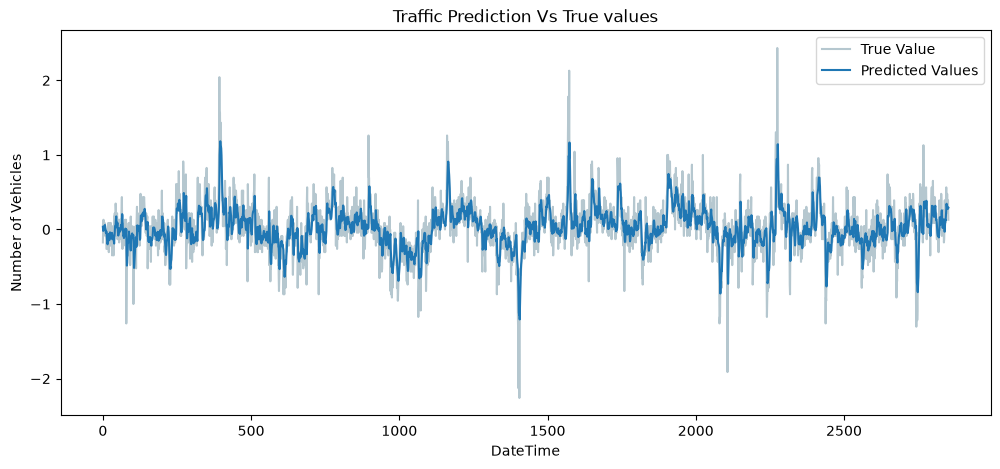

In [23]:
RMSE_LSTM = RMSE_Value(y_test, Pred_LSTM)
MAE_LSTM = MAE_Value(y_test, Pred_LSTM)
PredictionsPlot(y_test, Pred_LSTM, 0)